# 2. Egy HAR-X modell futtatása és ellenőrzése

1. Kiválasztasz egy modellt (6 beállítás), és a notebook lefuttatja – pontosan azzal a kóddal, amit a modell `model.py`-ja is hív.
2. Egy kiválasztott napra **kézzel** újrabecsüli az OLS-t (normálegyenletekkel), és összeveti az előrejelzéssel.
3. **Szivárgásteszt:** a nap utáni összes adatot véletlen zajra cseréli; az előrejelzésnek nem szabad megváltoznia.
4. A hibamérőt (QLIKE) kézzel újraszámolja.

A futtatás a modell `forecasts.csv`-jét ugyanazzal a tartalommal írja felül (a HAR determinisztikus).

In [1]:
# A projekt gyökerének megkeresése és a közös motor (src/) betöltése
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("projekt:", ROOT)

projekt: C:\Users\Tamás\Thesis_V3


In [2]:
# --- A modell beállításai (bármelyik a 128 HAR-modell közül) ----------------------------------
LEPCSO = "L2"            # L1, L2, L3, L4
TRANSZF = "Log"          # Log, QuarticRoot
ABLAK = "3Y"             # 2Y (500 nap), 3Y (750 nap)
GYAKORISAG = "Weekly"    # Weekly, Monthly
MERTEK = "RV"            # RV, RV_CJ, Parkinson, Garman_Klass

## 1. A modell futtatása

In [3]:
from config import model_dir
from runner import run_model

mappa = model_dir("HAR", LEPCSO, TRANSZF, ABLAK, GYAKORISAG, MERTEK)
korabbi = pd.read_csv(mappa / "forecasts.csv", index_col="date", parse_dates=True)

fc = run_model("HAR", LEPCSO, TRANSZF, ABLAK, GYAKORISAG, MERTEK)      # ugyanaz, mint a model.py

print("mappa:", mappa.relative_to(ROOT))
print(f"{len(fc)} előrejelzés: {fc.index.min().date()} – {fc.index.max().date()}")
print("legnagyobb eltérés a korábban tárolt előrejelzéstől:", np.max(np.abs(fc["sigma_hat"] - korabbi["sigma_hat"])))
fc.head()

mappa: models\HAR_L2_Macro\Log\3Y_Weekly\RV
1841 előrejelzés: 2018-08-30 – 2026-07-09
legnagyobb eltérés a korábban tárolt előrejelzéstől: 9.8879238130678e-17


,sigma_true,sigma_hat,y_true,y_hat,resid_var
date,,,,,
2018-08-30,0.010847,0.011999,-4.523849,-4.439971,0.034113
2018-09-04,0.015156,0.013285,-4.189385,-4.338146,0.034121
2018-09-05,0.015252,0.014124,-4.183076,-4.276941,0.034121
2018-09-06,0.014158,0.014342,-4.257506,-4.261653,0.034121
2018-09-07,0.014159,0.014020,-4.257415,-4.284366,0.034121


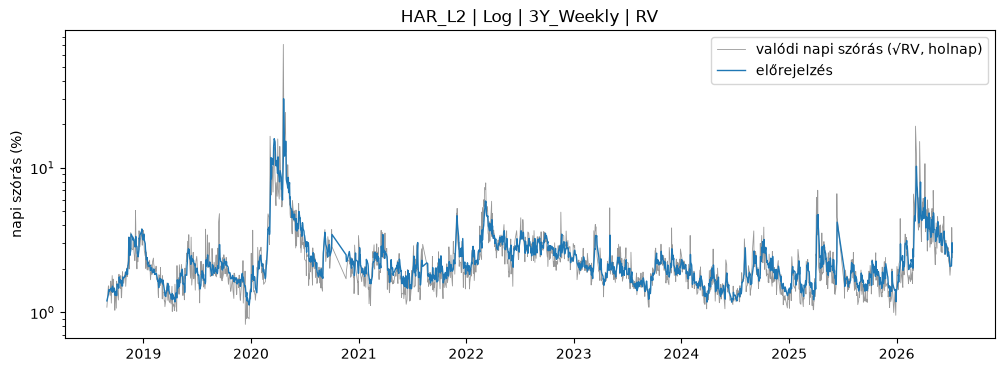

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(fc.index, fc["sigma_true"] * 100, lw=0.6, color="0.6", label="valódi napi szórás (√RV, holnap)")
ax.plot(fc.index, fc["sigma_hat"] * 100, lw=1, label="előrejelzés")
ax.set_ylabel("napi szórás (%)")
ax.set_yscale("log")
ax.set_title(f"HAR_{LEPCSO} | {TRANSZF} | {ABLAK}_{GYAKORISAG} | {MERTEK}")
ax.legend()
plt.show()

## 2. Egy nap előrejelzése kézzel

Az előrejelzés a legutóbbi újrabecslési napon becsült együtthatókkal készül. Az OLS **csak az újrabecslési nap előtti**
`ablak` darab napon tanul. Itt ezt kézzel megismételjük, a normálegyenletekkel: β = (X′X)⁻¹X′y.

In [5]:
from config import WINDOWS
from forecasting import load_model_data, refit_flags

DATUM = "2020-04-15"     # <- bármely nap az előrejelzési időszakból

X, y, sigma, dates, nevek = load_model_data(LEPCSO, TRANSZF, MERTEK)
w = WINDOWS[ABLAK]
i = dates.get_loc(pd.Timestamp(DATUM))
refit = refit_flags(dates, GYAKORISAG)
j = max(k for k in range(w, i + 1) if refit[k] or k == w)          # az utolsó újrabecslési nap

Xt = np.column_stack([np.ones(w), X[j - w:j]])                      # tanulóminta: j-w ... j-1
yt = y[j - w:j]
beta = np.linalg.solve(Xt.T @ Xt, Xt.T @ yt)                        # normálegyenletek
s2 = np.sum((yt - Xt @ beta) ** 2) / (w - Xt.shape[1])              # reziduális variancia
mu = np.r_[1.0, X[i]] @ beta                                        # transzformált előrejelzés
sigma_hat = np.exp(mu + s2 / 2) if TRANSZF == "Log" else max(mu, 0) ** 2 + s2   # visszaváltás

print(f"előrejelzés napja: {DATUM}  (cél: a következő kereskedési nap szórása)")
print(f"utolsó újrabecslés: {dates[j].date()};  tanulóminta: {dates[j - w].date()} – {dates[j - 1].date()}  ({w} nap)")
pd.DataFrame({"kézzel": [mu, s2, sigma_hat], "projekt (forecasts.csv)": fc.loc[DATUM, ["y_hat", "resid_var", "sigma_hat"]].to_numpy()},
             index=["y_hat (transzformált)", "reziduális variancia", "sigma_hat (napi szórás)"])

előrejelzés napja: 2020-04-15  (cél: a következő kereskedési nap szórása)
utolsó újrabecslés: 2020-04-13;  tanulóminta: 2017-02-09 – 2020-04-09  (750 nap)


,kézzel,projekt (forecasts.csv)
y_hat (transzformált),-2.577342,-2.577342
reziduális variancia,0.040670,0.040670
sigma_hat (napi szórás),0.077536,0.077536


In [6]:
# Az együtthatók: kézzel és a projekt coefficients.csv fájljából (ugyanazon az újrabecslési napon)
coefs = pd.read_csv(mappa / "coefficients.csv", index_col="refit_date", parse_dates=True)
pd.DataFrame({"kézzel": beta, "coefficients.csv": coefs.loc[dates[j], ["const", *nevek]].to_numpy()}, index=["const", *nevek])

,kézzel,coefficients.csv
const,0.445348,0.445348
har_d,0.296607,0.296607
har_w,0.113488,0.113488
har_m,-0.055818,-0.055818
ovx,0.579942,0.579942
vix,0.182051,0.182051
sp500,-0.003712,-0.003712
usd,-0.004033,-0.004033


## 3. Szivárgásteszt: nincs jövőbeli adat

A `DATUM` utáni összes magyarázó változót és a `DATUM`-tól kezdődő összes célértéket véletlen számokra cseréljük, és a teljes
gördülő becslést újrafuttatjuk. Ha a modell nem lát a jövőbe, a `DATUM`-ig készült előrejelzések **egyáltalán nem változnak**.

In [7]:
from har import rolling_ols

rng = np.random.default_rng(0)
X_rontott, y_rontott = X.copy(), y.copy()
X_rontott[i + 1:] = rng.normal(0, 10, X_rontott[i + 1:].shape)     # a DATUM utáni napok jellemzői
y_rontott[i:] = rng.normal(0, 10, len(y_rontott) - i)               # a DATUM-tól ismeretlen célok

mu_eredeti, _, _ = rolling_ols(X, y, dates, w, GYAKORISAG, nevek)
mu_rontott, _, _ = rolling_ols(X_rontott, y_rontott, dates, w, GYAKORISAG, nevek)
elotte = slice(w, i + 1)
print("legnagyobb eltérés a DATUM-ig:  ", np.nanmax(np.abs(mu_eredeti[elotte] - mu_rontott[elotte])))
print("legnagyobb eltérés a DATUM után:", np.nanmax(np.abs(mu_eredeti[i + 1:] - mu_rontott[i + 1:])), "(itt változnia kell)")

legnagyobb eltérés a DATUM-ig:   1.7763568394002505e-15
legnagyobb eltérés a DATUM után: 53.807110280502854 (itt változnia kell)


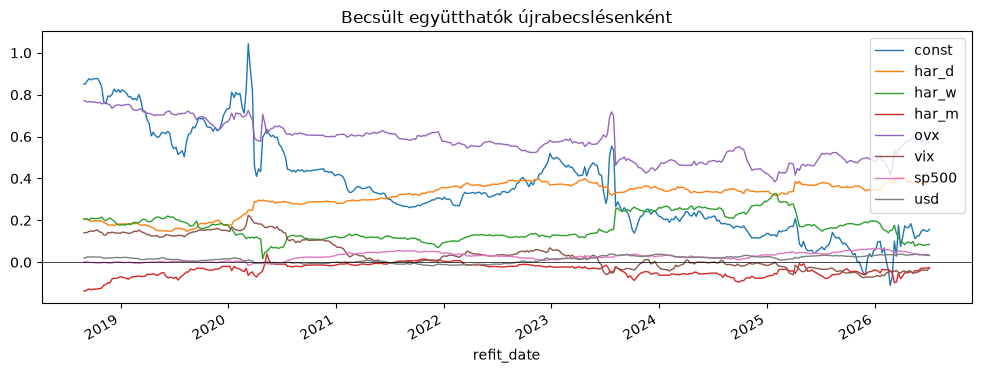

In [8]:
# Az együtthatók alakulása az újrabecslések során
ax = coefs.drop(columns=["resid_var"]).plot(figsize=(12, 4), lw=1)
ax.axhline(0, color="k", lw=0.5)
ax.set_title("Becsült együtthatók újrabecslésenként")
plt.show()

## 4. A hibamérő kézzel

A kiértékelés szórás-skálán történik, a közös kiértékelési időszakon (2018-08-30-tól, 1841 nap):
QLIKE = σ/σ̂ − ln(σ/σ̂) − 1.

In [9]:
e = fc[fc.index >= "2018-08-30"]
arany = e["sigma_true"] / e["sigma_hat"]
qlike_kezzel = np.mean(arany - np.log(arany) - 1)
mse_kezzel = np.mean((e["sigma_true"] - e["sigma_hat"]) ** 2)
metrics = pd.read_csv(mappa / "metrics.csv", index_col="sample")
print(f"napok: {len(e)}")
pd.DataFrame({"kézzel": [qlike_kezzel, mse_kezzel], "metrics.csv": metrics.loc["full", ["QLIKE", "MSE"]].to_numpy()},
             index=["QLIKE", "MSE"])

napok: 1841


,kézzel,metrics.csv
QLIKE,0.025238,0.025238
MSE,0.000272,0.000272
